# Learning the regimes: dictionary learning in the barycentric coding model

`moved_or_appeared.ipynb` used the barycentric coding model (BCM) to test whether a snapshot of a graph
signal is *transport-consistent*: whether it is a barycenter, in the discrete transport metric, of a few
known regimes. There the regimes were given. This notebook **learns them from unlabeled snapshots**.

Given frames $\nu_1, \dots, \nu_T$ and a number of atoms $k$, we look for atoms $\rho_1, \dots, \rho_k$
that make every frame a barycenter. The loss is the mean squared barycentric defect,

$$\mathcal L(\rho) = \frac1T \sum_t \min_{\lambda \in \Delta}
  \Big\| \sum_i \lambda_i \log_{\nu_t} \rho_i \Big\|^2_{\nu_t},$$

which is zero exactly when every frame is a barycenter of the atoms. The inner minimum is the BCM's
analysis step, a simplex quadratic program. Two facts make the loss trainable:

* **No differentiable barycenter is needed.** The loss is built from log maps at the frames, never from a
  synthesized barycenter.
* **The gradient is exact.** By the envelope theorem the analysis weights $\hat\lambda_t$ can be held
  fixed, so the gradient with respect to an atom flows only through the log maps $\log_{\nu_t}\rho_i$.
  `graphtransport` differentiates those exactly, by the implicit function theorem on the shooting
  problem.

The experiment is planted recovery on a 6×6 grid: three blob regimes, 30 frames synthesized from them,
and the question of whether training finds the regimes again. The short answer: **the optimizer
matters.** Adam passes close to the planted regimes and then settles in a different, worse basin.
L-BFGS-B recovers them.

Running this notebook takes a few minutes with its cached training runs, and about an hour when it
has to train (see `build_regime_learning.py`; the cache is not tracked in git). The machinery is in
`regime_learning.py`, next to this notebook.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

import graphtransport as gt
import regime_learning as rl

torch.set_num_threads(1)
warnings.filterwarnings("ignore", message=".*torch.jit.script.*", category=FutureWarning)

CACHE = Path("data/regime_learning_runs.npz")
TRAIN = False or not CACHE.exists()  # build_regime_learning.py --train retrains; otherwise load the cache
ANIMATIONS = Path("animations")

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
ALERT = "#e34948"
MASS = LinearSegmentedColormap.from_list(
    "mass", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
STYLE = {"ink": INK, "ink2": INK2, "muted": MUTED, "surface": SURFACE, "alert": ALERT, "mass": MASS}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "text.color": INK,
        "axes.titlesize": 11,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
        "legend.frameon": False,
    }
)

## 1. The planted problem

The graph is the 6×6 grid with its simple random walk. Each planted regime is a Gaussian blob of mass
in one corner or edge, mixed with 20% of uniform background, which keeps every density away from zero
as shooting needs. Two data sets of 30 frames each, both synthesized as SOCP barycenters ($N = 20$
time steps) at random Dirichlet(1, 1, 1) weights:

* **pure**: three of the 30 frames are the planted regimes themselves, the analog of the pure-pixel
  condition of hyperspectral unmixing;
* **mixed**: no frame is a planted regime.

The atoms start from three of the mixed frames, chosen at random, so training has to find its way
outward to the regimes.

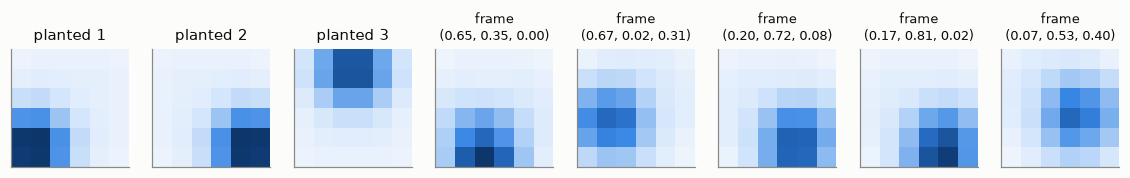

In [2]:
SIDE = 6
G = gt.MarkovGraph(*gt.grid_markov_chain(SIDE))
PI = G.pi
XY = np.array([(i % SIDE, i // SIDE) for i in range(G.n)], dtype=float)


def blob(center, width=1.2, floor=0.2):
    p = np.exp(-((XY - np.asarray(center)) ** 2).sum(1) / (2 * width**2))
    p = (1 - floor) * p / p.sum() + floor * PI
    return p / PI


PLANTED = [blob((0.5, 0.5)), blob((4.5, 0.5)), blob((2.5, 4.5))]


def make_data(pure: bool):
    """(weights, init indices): 30 Dirichlet(1,1,1) weight vectors, with the first three replaced by the
    vertices when pure; and three frames to start the atoms from, never a pure one."""
    rng = np.random.default_rng(0)
    lam = rng.dirichlet([1, 1, 1], size=30)
    if pure:
        lam[:3] = np.eye(3)
        init = np.random.default_rng(1).choice(np.arange(3, 30), 3, replace=False)
    else:
        init = rng.choice(30, 3, replace=False)
    return lam, init


def synth(lam):
    return gt.barycenter(G, PLANTED, lam, method="socp", N=20)[0]


DATA = {}
for name, pure in [("pure", True), ("mixed", False)]:
    lam, init = make_data(pure)
    DATA[name] = {"lam": lam, "init": init}
if TRAIN:
    import multiprocessing as mp

    with mp.get_context("fork").Pool(15) as pool:
        for name in DATA:
            DATA[name]["frames"] = np.array(pool.map(synth, list(DATA[name]["lam"])))
else:
    cached = np.load(CACHE)
    for name in DATA:
        DATA[name]["frames"] = cached[f"{name}_frames"]

vmax = max((r * PI).max() for r in PLANTED)
fig, axes = plt.subplots(1, 8, figsize=(13, 2.4))
for ax, r, title in zip(axes[:3], PLANTED, ["planted 1", "planted 2", "planted 3"], strict=True):
    ax.imshow((r * PI).reshape(SIDE, SIDE), cmap=MASS, vmin=0, vmax=vmax, origin="lower")
    ax.set_title(title, fontsize=10)
for ax, t in zip(axes[3:], range(3, 8), strict=True):
    w = DATA["pure"]["lam"][t]
    ax.imshow((DATA["pure"]["frames"][t] * PI).reshape(SIDE, SIDE), cmap=MASS, vmin=0, vmax=vmax, origin="lower")
    ax.set_title(f"frame\n({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})", fontsize=8.5)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

## 2. The gradient is exact

Before training, a check of the gradient the trainer uses: the derivative of the loss along a random
direction in the atoms' logits, from autograd and from central finite differences, for one frame.

In [3]:
frame = DATA["pure"]["frames"][5]
check = rl.Trainer(G, [frame], [DATA["pure"]["frames"][i] for i in DATA["pure"]["init"]], workers=1)
theta0 = check.theta.detach().clone()
_, grad, _, _ = check._loss_and_grad(theta0)
direction = torch.randn(theta0.shape, dtype=torch.float64, generator=torch.Generator().manual_seed(0))
eps = 1e-5
plus = check._loss_and_grad(theta0 + eps * direction)[0]
minus = check._loss_and_grad(theta0 - eps * direction)[0]
fd = (plus - minus) / (2 * eps)
print(f"autograd {float((grad * direction).sum()):.10e}")
print(f"finite differences {fd:.10e}")
check.close()

autograd -3.5064845710e-01
finite differences -3.5064628432e-01


The two agree to about five significant digits; the remaining gap is the finite difference's own
truncation and the log maps' Newton tolerance.

## 3. Training

Three runs, each from the same three starting frames for its data set:

| run | data | optimizer | budget |
|---|---|---|---|
| `adam_pure` | pure | Adam, learning rate 0.1 | 150 steps |
| `lbfgs_pure` | pure | L-BFGS-B, exact gradient | 80 iterations |
| `lbfgs_mixed` | mixed | L-BFGS-B, exact gradient | 200 iterations |

Each loss evaluation solves 90 log maps, 3 per frame, with their backward passes, spread over 15
processes: about 6 to 8 s. A record is kept at every Adam step and at every *accepted* L-BFGS-B iterate,
never at a line-search trial point.

In [4]:
RUNS = {
    "adam_pure": ("pure", "adam", 150),
    "lbfgs_pure": ("pure", "lbfgs", 80),
    "lbfgs_mixed": ("mixed", "lbfgs", 200),
}
runs, planted_loss = {}, {}
if TRAIN:
    arrays = {f"{name}_frames": DATA[name]["frames"] for name in DATA}
    for run_name, (data_name, method, budget) in RUNS.items():
        d = DATA[data_name]
        t0 = time.time()
        trainer = rl.Trainer(G, d["frames"], [d["frames"][i] for i in d["init"]])
        if method == "adam":
            trainer.adam(budget, lr=0.1)
        else:
            trainer.lbfgs(budget)
        runs[run_name] = trainer.run
        arrays.update(trainer.run.as_arrays(run_name))
        if data_name not in planted_loss:
            planted_loss[data_name] = trainer.loss_at(PLANTED)
            arrays[f"{data_name}_planted_loss"] = np.array(planted_loss[data_name])
        trainer.close()
        print(f"{run_name}: {len(trainer.run.loss)} records, {trainer.evals} evaluations, {time.time() - t0:.0f} s")
    CACHE.parent.mkdir(exist_ok=True)
    np.savez_compressed(CACHE, **arrays)
else:
    cached = np.load(CACHE)
    runs = {name: rl.Run.from_arrays(cached, name) for name in RUNS}
    planted_loss = {name: float(cached[f"{name}_planted_loss"]) for name in DATA}

t0 = time.time()
recov = {}
for name, run in runs.items():
    recov[name] = rl.recovery(G, run.atoms, PLANTED)
print(f"recovery errors for every record computed in {time.time() - t0:.0f} s")

recovery errors for every record computed in 73 s


In [5]:
rows = ["| run | records | evaluations | final loss | loss at the planted regimes | final W / D per atom |",
        "|---|---|---|---|---|---|"]
for name, run in runs.items():
    errs, perm, D = recov[name]
    data_name = RUNS[name][0]
    rows.append(
        f"| `{name}` | {len(run.loss)} | {int(run.evals[-1])} | {run.loss[-1]:.1e} | {planted_loss[data_name]:.1e} | "
        + ", ".join(f"{e:.3f}" for e in errs[-1])
        + " |"
    )
display(Markdown("\n".join(rows)))

| run | records | evaluations | final loss | loss at the planted regimes | final W / D per atom |
|---|---|---|---|---|---|
| `adam_pure` | 150 | 150 | 2.8e-04 | 4.4e-07 | 0.174, 0.178, 0.154 |
| `lbfgs_pure` | 81 | 87 | 1.9e-06 | 4.4e-07 | 0.032, 0.006, 0.010 |
| `lbfgs_mixed` | 201 | 207 | 5.9e-07 | 4.9e-07 | 0.010, 0.004, 0.005 |

## 4. Adam: close, then away

The filmstrip shows the atoms at selected steps, with the planted regimes outlined. The curves put the two
optimizers on a common axis: loss evaluations, the unit of cost.

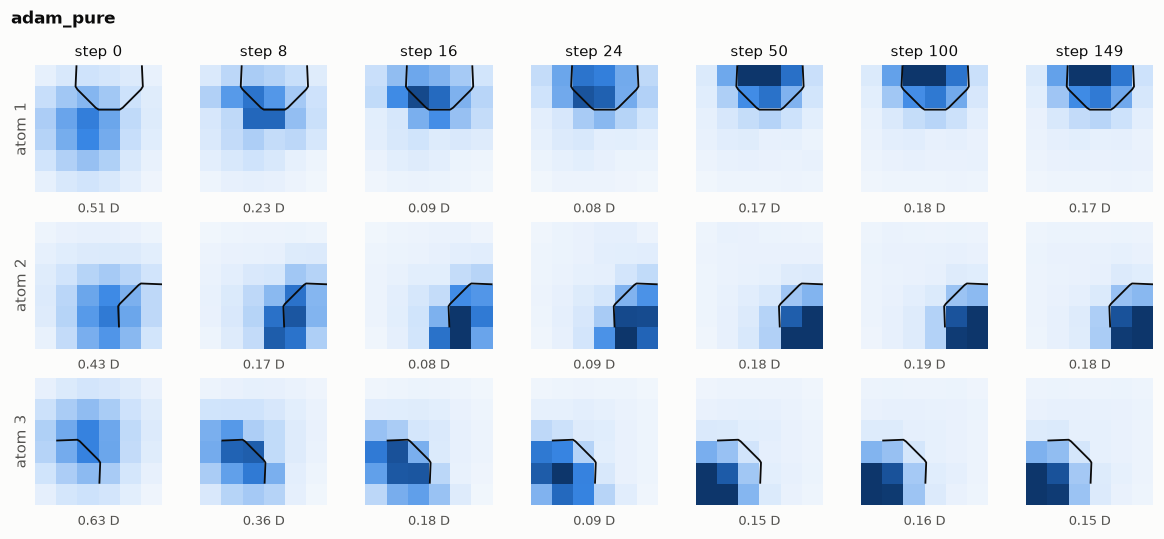

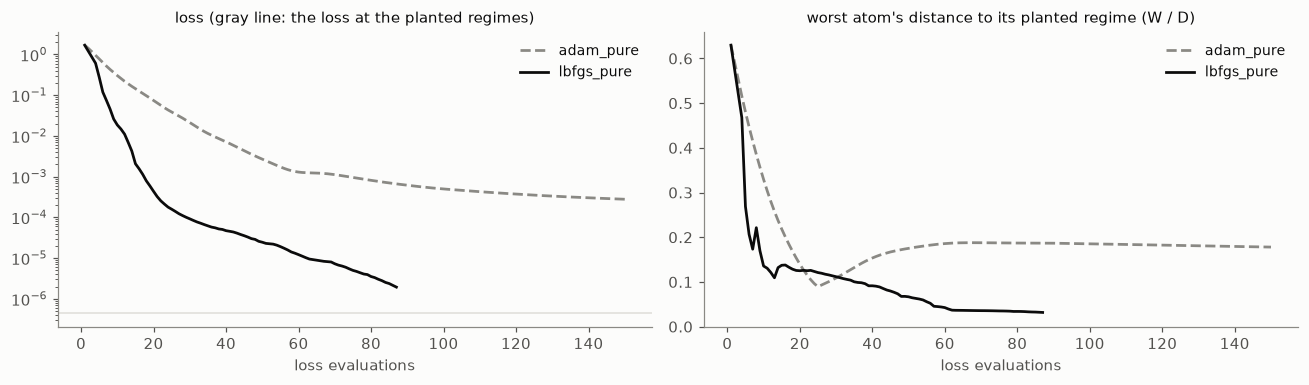

In [6]:
def filmstrip(name, picks, label):
    run, (errs, perm, D) = runs[name], recov[name]
    fig, axes = plt.subplots(3, len(picks), figsize=(1.55 * len(picks), 4.9))
    for j, s in enumerate(picks):
        for i in range(3):
            ax = axes[i, j]
            ax.imshow((run.atoms[s][i] * PI).reshape(SIDE, SIDE), cmap=MASS, vmin=0, vmax=vmax * 1.15, origin="lower")
            target = (PLANTED[perm[i]] * PI).reshape(SIDE, SIDE)
            ax.contour(target, levels=[0.5 * target.max()], colors=INK, linewidths=1.2, origin="lower")
            ax.set_xticks([])
            ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            ax.text(0.5, -0.08, f"{errs[s, i]:.2f} D", transform=ax.transAxes, ha="center", va="top", fontsize=8.5,
                    color=INK2)
        axes[0, j].set_title(f"{label} {s}", fontsize=9.5)
    for i in range(3):
        axes[i, 0].set_ylabel(f"atom {i + 1}", fontsize=9.5, color=INK2)
    fig.suptitle(name, x=0.02, ha="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()


best = int(recov["adam_pure"][0].max(1).argmin())
filmstrip("adam_pure", [0, 8, 16, best, 50, 100, 149], "step")


def curves(names):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    styles = {"adam_pure": (MUTED, "--"), "lbfgs_pure": (INK, "-"), "lbfgs_mixed": (INK2, ":")}
    for name in names:
        run, (errs, _, _) = runs[name], recov[name]
        c, ls = styles[name]
        axes[0].semilogy(run.evals, run.loss, color=c, ls=ls, lw=1.8, label=name)
        axes[1].plot(run.evals, errs.max(1), color=c, ls=ls, lw=1.8, label=name)
    for name in names:
        axes[0].axhline(planted_loss[RUNS[name][0]], color=GRID, lw=1)
    axes[0].set_title("loss (gray line: the loss at the planted regimes)", fontsize=10)
    axes[1].set_title("worst atom's distance to its planted regime (W / D)", fontsize=10)
    for ax in axes:
        ax.set_xlabel("loss evaluations")
        ax.legend(fontsize=9)
    axes[1].set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()


curves(["adam_pure", "lbfgs_pure"])

Adam brings every atom within about 0.09 D of its planted regime by step 24, then carries on.
The atoms grow more concentrated than the planted regimes and settle near 0.15 to 0.18 D away, while the
loss keeps falling. The loss at the planted regimes is far lower than where Adam ends, so Adam has not
found a different, equally good dictionary: it has stopped in a worse basin.

A slice of the loss along the straight line (in density) from Adam's last atoms to the planted regimes
shows the basin's wall. The same slice from the starting atoms shows no wall at all.

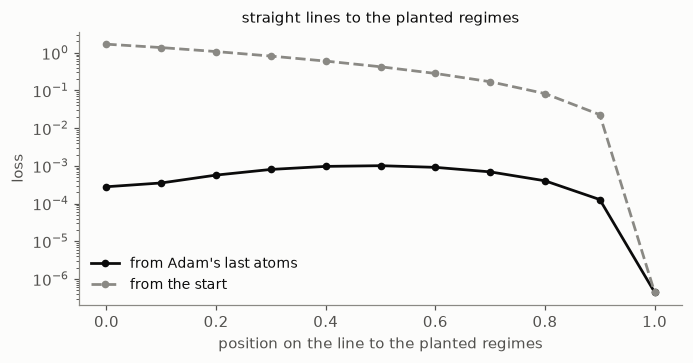

In [7]:
SLICE = np.linspace(0, 1, 11)
if TRAIN:
    d = DATA["pure"]
    slicer = rl.Trainer(G, d["frames"], PLANTED)
    perm = recov["adam_pure"][1]
    target = np.array(PLANTED)[list(perm)]
    slices = {}
    starts = {"from Adam's last atoms": runs["adam_pure"].atoms[-1], "from the start": runs["adam_pure"].atoms[0]}
    for label, start in starts.items():
        slices[label] = [slicer.loss_at((1 - s) * start + s * target) for s in SLICE]
    slicer.close()
    with np.load(CACHE) as old:
        arrays = dict(old)
    arrays["slice_adam_end"] = np.array(slices["from Adam's last atoms"])
    arrays["slice_start"] = np.array(slices["from the start"])
    np.savez_compressed(CACHE, **arrays)
else:
    cached = np.load(CACHE)
    slices = {"from Adam's last atoms": cached["slice_adam_end"], "from the start": cached["slice_start"]}

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for (label, values), (c, ls) in zip(slices.items(), [(INK, "-"), (MUTED, "--")], strict=True):
    ax.semilogy(SLICE, values, color=c, ls=ls, lw=1.8, marker="o", ms=4, label=label)
ax.set_xlabel("position on the line to the planted regimes")
ax.set_ylabel("loss")
ax.legend(fontsize=9)
ax.set_title("straight lines to the planted regimes", fontsize=10)
plt.tight_layout()
plt.show()

## 5. L-BFGS-B: recovery

The same data and the same starting atoms, with scipy's L-BFGS-B on the exact gradient. Every record is
an accepted iterate.

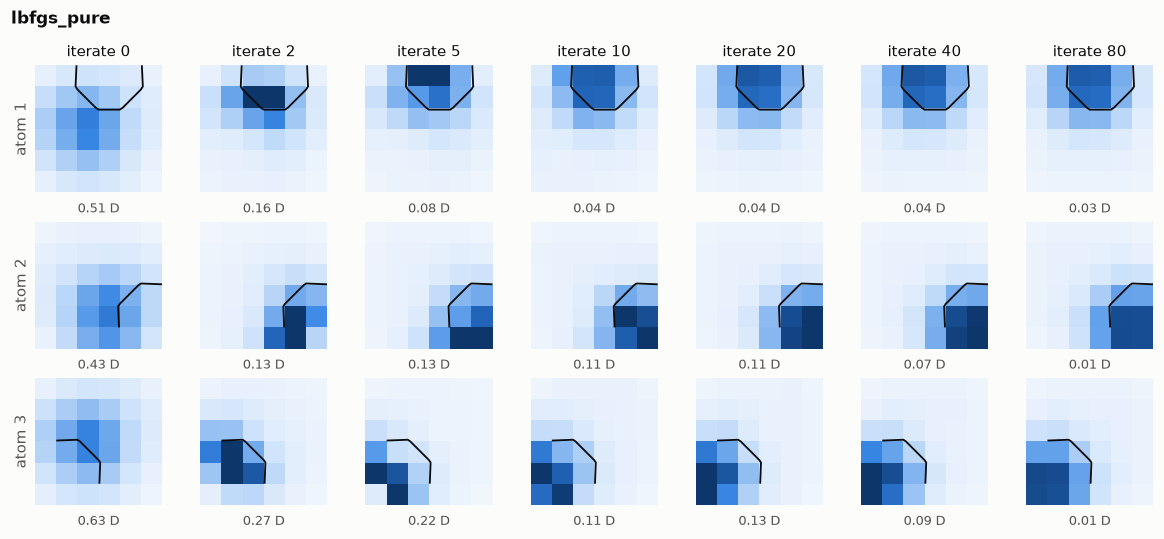

In [8]:
filmstrip("lbfgs_pure", [0, 2, 5, 10, 20, 40, len(runs["lbfgs_pure"].loss) - 1], "iterate")

L-BFGS-B's worst atom reaches 0.17 D by the fourth iterate, jumps back to 0.22 D at the fifth, and
then holds near 0.13 D for about twenty iterates before closing in. After 80 iterations the atoms are
0.032, 0.006 and 0.010 D from the planted regimes and
the loss is within a factor of five of the planted regimes' loss, still falling (the curves in section 4).
The same data and the same start, so the difference from Adam is the optimizer alone. A plausible reason,
not tested here: Adam scales each logit's step by that logit's own gradient history, so the logits of
nearly empty nodes, whose gradients are tiny, still take full-size steps; draining mass from the atoms'
tails is exactly the over-concentration in Adam's filmstrip.

## 6. Without pure frames

The mixed data set has no frame at a planted regime, so the frames alone do not mark where the regimes
are. This is where non-identifiability would show: once every frame is inside the atoms' barycentric
hull the loss is zero, and atoms pushed further out along their geodesics might fit just as well.

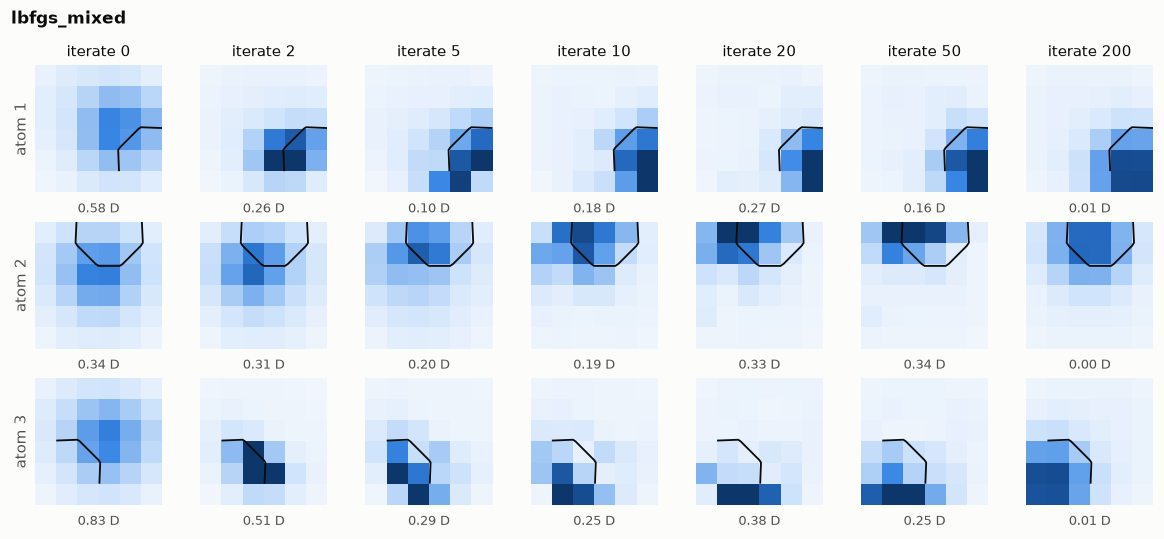

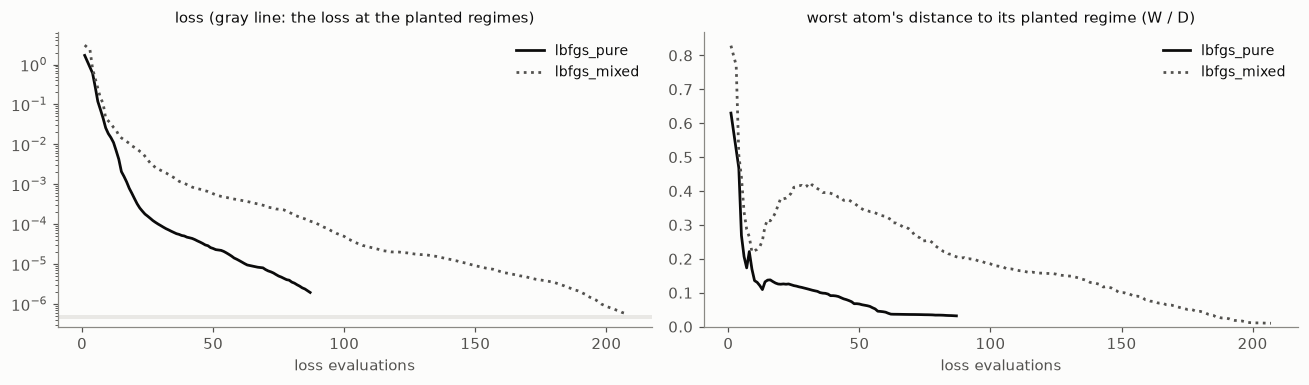

In [9]:
filmstrip("lbfgs_mixed", [0, 2, 5, 10, 20, 50, len(runs["lbfgs_mixed"].loss) - 1], "iterate")
curves(["lbfgs_pure", "lbfgs_mixed"])

Without pure frames the trajectory is longer. By about the 25th iterate the atoms have swung out to
0.42 D, more concentrated than the planted regimes. They then return, and after 200 iterations they are
0.010, 0.004 and 0.005 D from the planted regimes, with a loss of 5.9e-7 against the planted regimes'
4.9e-7.

So on this instance the planted regimes are recovered **without any frame at a regime**. The enlarged
dictionaries the trajectory passed through all had a clearly higher loss than the planted one: the
geometry does not let a bigger dictionary fit as well, which in a flat space it would. This is one data
set and one starting point, not a theorem. Whether it holds across draws, numbers of frames, noise and
graphs is the next experiment, and so is whether a linear model on the same frames could tell its
atoms apart from bigger ones (it could not, by the flat-space argument).

## 7. Animations

The cell below writes one animation per run to `animations/`: the atoms with the planted regimes
outlined, the frames' coordinates in the atoms' simplex (red while a frame is outside the atoms'
barycentric hull), the loss and the recovery error, one animation frame per record.

In [10]:
ANIMATIONS.mkdir(exist_ok=True)
t0 = time.time()
for name, run in runs.items():
    errs, perm, D = recov[name]
    data_name = RUNS[name][0]
    label = "step" if RUNS[name][1] == "adam" else "iterate"
    rl.animate(run, PLANTED, errs, perm, D, DATA[data_name]["lam"], SIDE, PI, str(ANIMATIONS / f"{name}.gif"),
               xlabel=label, style=STYLE)
print(f"wrote {', '.join(f'animations/{n}.gif' for n in runs)} in {time.time() - t0:.0f} s")

wrote animations/adam_pure.gif, animations/lbfgs_pure.gif, animations/lbfgs_mixed.gif in 103 s
